# MNIST：比较 MLP / CNN，以及 Sigmoid / Tanh / ReLU

这份笔记做一件事：用同一套训练流程，比较两种网络、三种激活函数。从上往下，每次运行一格（`Shift + Enter`），先读说明再看代码。

先记住三句话：

1. 一张图进去，网络吐出 10 个分数，哪个最大，就预测成哪个数字。
2. 训练就是让「猜错的程度」（损失）变小，方法是按梯度去改权重。
3. 这次只改两处：网络结构、激活函数。学习率、批大小、训练轮数全部相同，这样差距才能归因到这两处。

右上角的 Kernel 选 **Python (mnist)**。还没建环境的话，先在终端执行聊天里的 conda 命令。

## 1. 准备工具，并选定计算设备

`torch` 是 PyTorch。有 NVIDIA GPU 且驱动正常时用 GPU，否则用 CPU，后面的代码不用改。

In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [ ]:
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

BATCH_SIZE = 128
EPOCHS = 5
LEARNING_RATE = 1e-3
SEED = 0

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("设备:", device)
print("PyTorch:", torch.__version__)

设备: cuda
PyTorch: 2.15.0+cu134


## 2. 先用眼睛看数据

MNIST 是手写数字。训练集 60000 张，测试集 10000 张。每张图 28×28，灰度，标签是 0 到 9。

`ToTensor()` 把像素从 0–255 的整数变成 0–1 的小数，形状变成 `1×28×28`。开头的 `1` 是通道数：灰度图只有一个通道，彩图一般是 3 个。

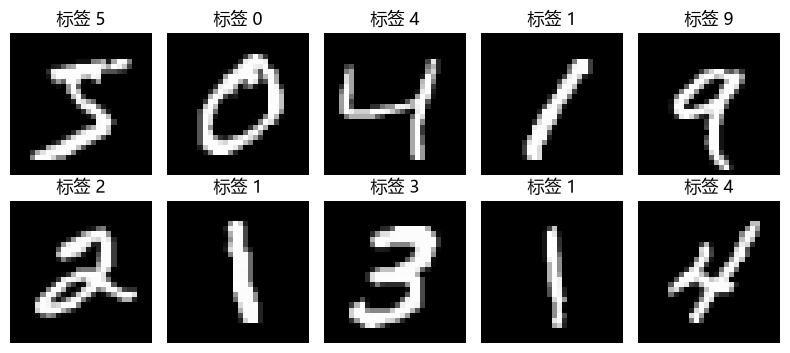

一张图的形状: (1, 28, 28)
标签: 5
像素最小值 / 最大值: 0.0 1.0
训练集张数: 60000


In [2]:
raw_set = datasets.MNIST(
    root="data",
    train=True,
    download=True,
    transform=transforms.ToTensor(),
)

fig, axes = plt.subplots(2, 5, figsize=(8, 3.6))
for ax, index in zip(axes.ravel(), range(10)):
    image, label = raw_set[index]
    ax.imshow(image.squeeze(), cmap="gray")
    ax.set_title(f"标签 {label}")
    ax.axis("off")
plt.tight_layout()
plt.show()

image0, label0 = raw_set[0]
print("一张图的形状:", tuple(image0.shape))
print("标签:", label0)
print("像素最小值 / 最大值:", float(image0.min()), float(image0.max()))
print("训练集张数:", len(raw_set))

## 3. 把数据整理成网络能吃的批次

训练前再做一次标准化：减去均值、除以标准差。MNIST 常用的数是均值 `0.1307`、标准差 `0.3081`。这样做之后像素有正有负，Tanh 和后面的网络都更好训。六组实验用同一套预处理。

`DataLoader` 每次拿出 `BATCH_SIZE` 张图，叫做一个 batch。一次把 6 万张都送进去会占很多内存，也更难更新权重。训练集打乱顺序，测试集保持原样。

In [3]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,)),
])

train_set = datasets.MNIST(root="data", train=True, download=True, transform=transform)
test_set = datasets.MNIST(root="data", train=False, download=True, transform=transform)

train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_set, batch_size=256, shuffle=False)

images, labels = next(iter(train_loader))
print("一个 batch 的图像:", tuple(images.shape))  # (128, 1, 28, 28)
print("一个 batch 的标签:", tuple(labels.shape))  # (128,)
print("标签示例:", labels[:10].tolist())

一个 batch 的图像: (128, 1, 28, 28)
一个 batch 的标签: (128,)
标签示例: [4, 7, 3, 6, 1, 1, 2, 6, 0, 5]


## 4. 激活函数

线性层做的是「加权求和」。只堆线性层，整个网络仍然等价于一层线性层，学不会弯曲的分界。激活函数接在线性层后面，给网络非线性。

- **Sigmoid**：压到 0 和 1 之间。早期常用，层数一深，梯度容易变得很小，学得慢。
- **Tanh**：压到 -1 和 1 之间，以 0 为中心，一般比 Sigmoid 好训。
- **ReLU**：负数变成 0，正数原样通过。现在最常用，计算简单，也更容易训深一点的网络。

分类网络的最后一层只留 `Linear`，输出 10 个原始分数（logits）。`CrossEntropyLoss` 会自己把分数变成概率再和标签比较。

In [4]:
def get_activation(name):
    if name == "sigmoid":
        return nn.Sigmoid()
    if name == "tanh":
        return nn.Tanh()
    if name == "relu":
        return nn.ReLU()
    raise ValueError(f"未知激活函数: {name}")


def init_linear(layer, activation_name):
    """ReLU 用 Kaiming，Sigmoid / Tanh 用 Xavier。先当作固定步骤。"""
    if activation_name == "relu":
        nn.init.kaiming_normal_(layer.weight, nonlinearity="relu")
    else:
        nn.init.xavier_normal_(layer.weight)
    nn.init.zeros_(layer.bias)

## 5. MLP：把图拉直，再一层层全连接

MLP（多层感知机）不看「这个像素旁边是谁」。它把 28×28 拉成 784 个数，然后：

`784 → 256 → 激活 → 128 → 激活 → 10`

`nn.Module` 是所有模型的基类。`__init__` 里把层建好，`forward` 里规定数据怎么流过去。`nn.Sequential` 就是按写好的顺序依次执行。

In [5]:
class MLP(nn.Module):
    def __init__(self, activation_name):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28, 256),
            get_activation(activation_name),
            nn.Linear(256, 128),
            get_activation(activation_name),
            nn.Linear(128, 10),
        )
        for layer in self.net:
            if isinstance(layer, nn.Linear):
                init_linear(layer, activation_name)

    def forward(self, x):
        return self.net(x)

## 6. CNN：先看一小块邻域，再缩小

卷积核在图上滑动，每个位置都看周围一小块，所以它知道笔画的局部形状。`padding=1`、`kernel_size=3` 时，高和宽保持 28。

`MaxPool2d(2)` 把高宽各砍一半：28 → 14 → 7。两次池化之后，64 个通道、7×7，拉直就是 `64×7×7 = 3136` 个数，再接两层全连接得到 10 个分数。

结构：

`Conv 1→32 → 激活 → 池化 → Conv 32→64 → 激活 → 池化 → 拉直 → 128 → 激活 → 10`

In [6]:
class CNN(nn.Module):
    def __init__(self, activation_name):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            get_activation(activation_name),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            get_activation(activation_name),
            nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128),
            get_activation(activation_name),
            nn.Linear(128, 10),
        )
        for layer in list(self.features) + list(self.classifier):
            if isinstance(layer, (nn.Linear, nn.Conv2d)):
                init_linear(layer, activation_name)

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

## 7. 先确认形状

模型写完先用一个 batch 跑一下。输入应是 `(128, 1, 28, 28)`，输出应是 `(128, 10)`。输出的 10 对应 10 个数字的分数。这里的模型只是检查用，正式训练时会重新创建。

In [7]:
probe = CNN("relu").to(device)
logits = probe(images.to(device))
print("CNN 输出形状:", tuple(logits.shape))

probe_mlp = MLP("relu").to(device)
print("MLP 输出形状:", tuple(probe_mlp(images.to(device)).shape))

def count_params(model):
    return sum(p.numel() for p in model.parameters())

print("MLP 参数量:", count_params(probe_mlp))
print("CNN 参数量:", count_params(probe))

CNN 输出形状: (128, 10)
MLP 输出形状: (128, 10)
MLP 参数量: 235146
CNN 参数量: 421642


## 8. 一轮训练在做什么

一个 epoch 就是把训练集完整看一遍。每个 batch 走五步：

1. `optimizer.zero_grad()`：清掉上一个 batch 留下的梯度。
2. `logits = model(images)`：前向，算出 10 个分数。
3. `loss = loss_fn(logits, labels)`：和正确答案比，得到一个数。越大说明错得越厉害。
4. `loss.backward()`：从损失往回算，每个权重该往哪边改。
5. `optimizer.step()`：按学习率真正改权重。

预测类别是这 10 个分数里最大的那个，`argmax(dim=1)`。准确率 = 猜对的张数 / 总张数。

测试时调用 `model.eval()`，并用 `torch.no_grad()`：只看效果，不改权重。

In [8]:
def accuracy_from_logits(logits, labels):
    preds = logits.argmax(dim=1)
    return (preds == labels).sum().item()


def train_one_epoch(model, loader, optimizer, loss_fn):
    model.train()
    total_loss = 0.0
    correct = 0
    total = 0
    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        logits = model(images)
        loss = loss_fn(logits, labels)
        loss.backward()
        optimizer.step()

        batch_size = images.size(0)
        total_loss += loss.item() * batch_size
        correct += accuracy_from_logits(logits, labels)
        total += batch_size
    return total_loss / total, correct / total


def evaluate(model, loader, loss_fn):
    model.eval()
    total_loss = 0.0
    correct = 0
    total = 0
    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)
            logits = model(images)
            loss = loss_fn(logits, labels)
            batch_size = images.size(0)
            total_loss += loss.item() * batch_size
            correct += accuracy_from_logits(logits, labels)
            total += batch_size
    return total_loss / total, correct / total

## 9. 六组用同一套流程跑

2 种网络 × 3 种激活 = 6 次。每次都先 `manual_seed`，再新建模型，避免上一轮的权重和随机数串到下一轮。

优化器都用 Adam，学习率都是上面的 `LEARNING_RATE`。这一格会训练一会儿：GPU 上通常几分钟，CPU 上会更久。中间会打印每一轮的训练准确率和测试准确率。

In [9]:
def set_seed(seed):
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def run_experiment(model_name, activation_name):
    set_seed(SEED)
    model = MLP(activation_name) if model_name == "MLP" else CNN(activation_name)
    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    loss_fn = nn.CrossEntropyLoss()

    history = {"train_loss": [], "train_acc": [], "test_loss": [], "test_acc": []}
    print(f"\n===== {model_name} + {activation_name}  参数量 {count_params(model)} =====")
    for epoch in range(1, EPOCHS + 1):
        train_loss, train_acc = train_one_epoch(model, train_loader, optimizer, loss_fn)
        test_loss, test_acc = evaluate(model, test_loader, loss_fn)
        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["test_loss"].append(test_loss)
        history["test_acc"].append(test_acc)
        print(
            f"epoch {epoch}: "
            f"train loss {train_loss:.4f} acc {train_acc:.4f} | "
            f"test loss {test_loss:.4f} acc {test_acc:.4f}"
        )

    return {
        "model": model_name,
        "activation": activation_name,
        "params": count_params(model),
        "history": history,
    }


results = []
for model_name in ("MLP", "CNN"):
    for activation_name in ("sigmoid", "tanh", "relu"):
        results.append(run_experiment(model_name, activation_name))


===== MLP + sigmoid  参数量 235146 =====
epoch 1: train loss 0.4716 acc 0.8815 | test loss 0.2132 acc 0.9388
epoch 2: train loss 0.1692 acc 0.9510 | test loss 0.1393 acc 0.9600
epoch 3: train loss 0.1093 acc 0.9690 | test loss 0.1040 acc 0.9697
epoch 4: train loss 0.0769 acc 0.9785 | test loss 0.0859 acc 0.9732
epoch 5: train loss 0.0567 acc 0.9844 | test loss 0.0764 acc 0.9758

===== MLP + tanh  参数量 235146 =====
epoch 1: train loss 0.2446 acc 0.9268 | test loss 0.1272 acc 0.9634
epoch 2: train loss 0.0993 acc 0.9706 | test loss 0.0939 acc 0.9705
epoch 3: train loss 0.0626 acc 0.9813 | test loss 0.0862 acc 0.9732
epoch 4: train loss 0.0450 acc 0.9862 | test loss 0.0860 acc 0.9724
epoch 5: train loss 0.0347 acc 0.9889 | test loss 0.0775 acc 0.9747

===== MLP + relu  参数量 235146 =====
epoch 1: train loss 0.2313 acc 0.9287 | test loss 0.1138 acc 0.9649
epoch 2: train loss 0.0920 acc 0.9713 | test loss 0.0967 acc 0.9693
epoch 3: train loss 0.0614 acc 0.9806 | test loss 0.0810 acc 0.9752
epoch

## 10. 把六组结果放在一起看

曲线看「谁涨得快」。表格看最后一轮的测试准确率。参数量一起看：CNN 和 MLP 的权重大小不同，准确率高的那一个，也可能只是因为参数更多。作业里把参数量写在结论旁边。

读的时候可以先回答这三句：

1. 同一种激活下，CNN 和 MLP 谁的测试准确率更高？
2. 同一种网络下，三种激活谁最高、谁最慢？
3. 训练准确率明显高于测试准确率时，说明模型记住了训练图。这次网络不大、数据也简单，两者通常很接近。

 模型    激活函数    参数量  最终测试准确率   最终测试损失
CNN    tanh 421642   0.9907 0.028159
CNN    relu 421642   0.9891 0.033005
CNN sigmoid 421642   0.9860 0.048275
MLP    relu 235146   0.9771 0.076410
MLP sigmoid 235146   0.9758 0.076435
MLP    tanh 235146   0.9747 0.077507


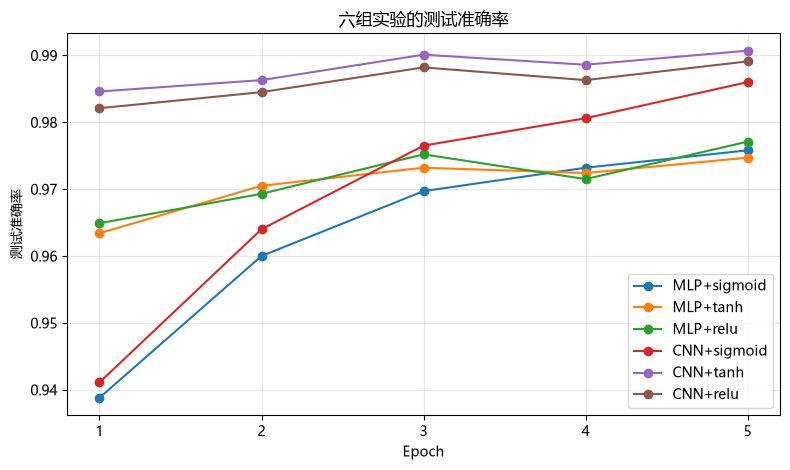

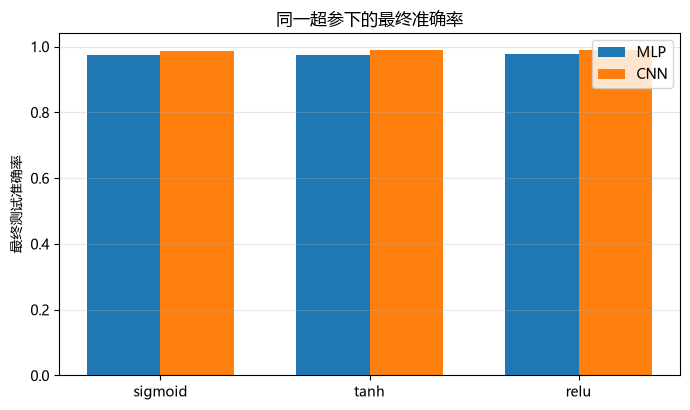

In [10]:
summary = pd.DataFrame([
    {
        "模型": record["model"],
        "激活函数": record["activation"],
        "参数量": record["params"],
        "最终测试准确率": record["history"]["test_acc"][-1],
        "最终测试损失": record["history"]["test_loss"][-1],
    }
    for record in results
])
summary = summary.sort_values("最终测试准确率", ascending=False).reset_index(drop=True)
print(summary.to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 4.8))
for record in results:
    epochs = range(1, EPOCHS + 1)
    label = f"{record['model']}+{record['activation']}"
    ax.plot(epochs, record["history"]["test_acc"], marker="o", label=label)
ax.set_xlabel("Epoch")
ax.set_ylabel("测试准确率")
ax.set_title("六组实验的测试准确率")
ax.set_xticks(list(range(1, EPOCHS + 1)))
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

activations = ["sigmoid", "tanh", "relu"]
x = np.arange(len(activations))
width = 0.35
fig, ax = plt.subplots(figsize=(7, 4.2))
for i, model_name in enumerate(("MLP", "CNN")):
    accs = []
    for activation_name in activations:
        record = next(
            r for r in results
            if r["model"] == model_name and r["activation"] == activation_name
        )
        accs.append(record["history"]["test_acc"][-1])
    ax.bar(x + (i - 0.5) * width, accs, width, label=model_name)
ax.set_xticks(x)
ax.set_xticklabels(activations)
ax.set_ylabel("最终测试准确率")
ax.set_title("同一超参下的最终准确率")
ax.legend()
ax.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
plt.show()